In [1]:
from qiskit import *
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, thermal_relaxation_error
import matplotlib.pyplot as plt
from qutip import Qobj, fidelity, tracedist, concurrence, qeye, entropy_vn, basis, tensor, fidelity, tracedist, concurrence, partial_transpose
import scienceplots
import pandas as pd

## Tomography Singlet 

In [2]:
def entanglement(n=0):
    """
    Create a singlet state (|01> - |10>)/sqrt(2) between Alice and Bob,
    optionally moving Bob's qubit through a chain of SWAP operations
    into auxiliary qubits ("ext").
    
    Args:
        n (int): number of extra qubits (length of the SWAP chain).
    
    Returns:
        QuantumCircuit: Qiskit circuit with the entangled state.
    """

    # 1) Create quantum registers for Alice and Bob
    alice = QuantumRegister(1, 'Alice')
    bob   = QuantumRegister(1, 'Bob')
    regs_q = [alice, bob]

    # 2) If n > 0, add auxiliary register "ext" with n qubits
    if n > 0:
        ext = QuantumRegister(n, 'ext')
        regs_q.append(ext)

    # 3) Create classical register (for measurement if needed)
    c = ClassicalRegister(2, 'c')

    # 4) Build the circuit including all registers
    qc = QuantumCircuit(*regs_q, c, name=f'entanglement(n={n})')

    # 5) Prepare the singlet state: (|01> - |10>)/sqrt(2)
    qc.x(bob[0])          # Bob in |1>
    qc.h(alice[0])        # Alice in (|0> + |1>)/sqrt(2)
    qc.cx(alice[0], bob[0])
    qc.z(bob[0])          # Flip the phase of |10>

    # 6) If n > 0, apply a SWAP chain: Bob ↔ ext[0] ↔ ext[1] ↔ ...
    if n > 0:
        qc.swap(bob[0], ext[0])
        for i in range(1, n):
            qc.swap(ext[i-1], ext[i])

    return qc

## Def Circuit

In [3]:
# List of Pauli matrices
pauli_list = [
    np.eye(2, dtype=complex),                        # I
    np.array([[0, 1], [1, 0]], dtype=complex),       # X
    np.array([[0, -1j], [1j, 0]], dtype=complex),    # Y
    np.array([[1, 0], [0, -1]], dtype=complex),      # Z
]

def measurement_circuit2q(i, j, input_circuit, targetA, targetB):
    """
    Create a circuit that measures targetA in Pauli basis i,
    and targetB in Pauli basis j.
    
    Args:
        i (str or int): Pauli basis for Alice ('X','Y','Z' or 1,2,3).
        j (str or int): Pauli basis for Bob   ('X','Y','Z' or 1,2,3).
        input_circuit (QuantumCircuit): circuit preparing the state.
        targetA, targetB (int): qubit indices.
    
    Returns:
        QuantumCircuit: copy of input_circuit with measurement appended.
    """
    circ = input_circuit.copy()

    # Normalize i, j to string labels
    if isinstance(i, int):
        label_map = ['I','X','Y','Z']
        i = label_map[i]
    if isinstance(j, int):
        label_map = ['I','X','Y','Z']
        j = label_map[j]

    # Basis change for qubit A
    if i == 'X':
        circ.h(targetA)
    elif i == 'Y':
        circ.sdg(targetA)
        circ.h(targetA)

    # Basis change for qubit B
    if j == 'X':
        circ.h(targetB)
    elif j == 'Y':
        circ.sdg(targetB)
        circ.h(targetB)

    # Classical register for results
    creg = ClassicalRegister(2, 'c_tom')
    circ.add_register(creg)

    # Measurements
    circ.measure(targetA, creg[0])
    circ.measure(targetB, creg[1])
    
    return circ


In [4]:
# --- Função de negatividade ---
def negativity(rho, subsys=1):
    mask = [idx == subsys for idx, _ in enumerate(rho.dims[0])]
    rho_pt = partial_transpose(rho, mask)
    eigs = rho_pt.eigenenergies()
    return 2*sum(abs(l) for l in eigs if l < 0)

In [5]:
def tomography2q_Noises(my_circuit, targetA, targetB, shots):
    """Performs 2-qubit state tomography with noise"""

    bases = ['I', 'X', 'Y', 'Z']
    expectation = {}

    for i in bases:
        for j in bases:

            if i == 'I' and j == 'I':
                expectation[(i, j)] = 1.0
                continue

            # Create measurement circuit
            circ = measurement_circuit2q(i, j, my_circuit, targetA, targetB)

            tcirc = transpile(
                circ,
                backend,
                basis_gates=['swap','h','x','y','z','cx','measure','sdg'],
                optimization_level=0
            )

            # Run circuit
            result = backend.run(tcirc, shots=shots).result()
            counts = result.get_counts()

            # Probabilities
            p00 = sum(cnt for bits, cnt in counts.items() if bits[1]=='0' and bits[0]=='0')
            p01 = sum(cnt for bits, cnt in counts.items() if bits[1]=='0' and bits[0]=='1')
            p10 = sum(cnt for bits, cnt in counts.items() if bits[1]=='1' and bits[0]=='0')
            p11 = sum(cnt for bits, cnt in counts.items() if bits[1]=='1' and bits[0]=='1')

            total = p00 + p01 + p10 + p11
            if total == 0:
                total = 1

            # Expectation value
            if i == 'I' and j != 'I':
                Eij = (p00 + p10 - p01 - p11) / total
            elif j == 'I' and i != 'I':
                Eij = (p00 + p01 - p10 - p11) / total
            else:
                Eij = (p00 - p01 - p10 + p11) / total

            expectation[(i, j)] = float(Eij)

    # Density matrix reconstruction
    rho = np.zeros((4,4), dtype=complex)

    for ii, i in enumerate(bases):
        for jj, j in enumerate(bases):
            rho += expectation[(i,j)] * np.kron(pauli_list[ii], pauli_list[jj])

    rho = rho / 4.0

    # Convert to QuTiP object
    rho_real = Qobj(rho)

    return rho_real

## Noise Despolarizing


In [6]:
# --- Create noise model ---
noise_model = NoiseModel()

# Depolarizing error: probability p of the state becoming completely mixed
p2 = 0.02  # 2-qubit error
gate_time_2q = 200    # 2-qubit gate time in ns


error_2q = depolarizing_error(p2, 2)



noise_model.add_all_qubit_quantum_error(error_2q, ["swap"])

# Measurement error
meas_error = depolarizing_error(0.02, 1)
noise_model.add_all_qubit_quantum_error(meas_error, ["measure"])

# Backend with noise
backend = AerSimulator(noise_model=noise_model)

In [7]:
psi_singlet = (1/np.sqrt(2)) * np.array([0, 1, -1, 0])
rho_ideal = np.outer(psi_singlet, psi_singlet.conj())

rho_ideal = Qobj(rho_ideal)


In [ ]:
# Maximum number of SWAPs
num_swaps = 13

# --- Estado ideal (singlete) ---
psi_singlet = (1/np.sqrt(2)) * np.array([0, 1, -1, 0])
rho_ideal = Qobj(
    np.outer(psi_singlet, psi_singlet.conj()),
    dims=[[2,2],[2,2]]
)
# Guardar resultados
results = []

for n in range(0, num_swaps + 1):
    
    circuit = entanglement(n)
    rho = tomography2q_Noises(circuit, targetA=0, targetB=n+1, shots=2000000)

    # ⚠️ GARANTIR dims antes de tudo
    rho = Qobj(rho.full(), dims=[[2,2],[2,2]])

    # --- Métricas ---
    F = fidelity(rho_ideal, rho)
    D = tracedist(rho_ideal, rho)
    C = concurrence(rho)
    N_val = negativity(rho)

    # --- Armazena ---
    results.append({
        "SWAPs": n,
        "Fidelity": F,
        "Trace Distance": D,
        "Concurrence": C,
        "Negativity": N_val
    })

# DataFrame
df_results_desp = pd.DataFrame(results)
print(df_results_desp.round(6))


c:\Users\Grupo Nemes\AppData\Local\Programs\Python\Python312\Lib\site-packages\qiskit\transpiler\preset_passmanagers\generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(


    SWAPs  Fidelity  Trace Distance  Concurrence  Negativity
0       0  0.985124        0.029534     0.940942    0.940938
1       1  0.977683        0.044140     0.911744    0.911728
2       2  0.970490        0.058157     0.883713    0.883703
3       3  0.963251        0.072151     0.855715    0.855705
4       4  0.956435        0.085234     0.829541    0.829536
5       5  0.949372        0.098695     0.802619    0.802616
6       6  0.942381        0.111919     0.776167    0.776165
7       7  0.935350        0.125121     0.749765    0.749761
8       8  0.929018        0.136927     0.726155    0.726150
9       9  0.922289        0.149383     0.701238    0.701235
10     10  0.915759        0.161387     0.677236    0.677231
11     11  0.909281        0.173208     0.653586    0.653585
12     12  0.902781        0.184988     0.630029    0.630029


## T omography Singlet (Amplitude Damping)

In [9]:
noise_model = NoiseModel()

T1 = 146.91e3
T2 = 62.35e3
gate_time = 200

# erro de 1 qubit
single_error = thermal_relaxation_error(T1, T2, gate_time)

# erro de 2 qubits (SWAP)
two_qubit_error = single_error.tensor(single_error)


noise_model.add_all_qubit_quantum_error(
    two_qubit_error, ["cx", "swap"]
)

meas_error = thermal_relaxation_error(T1, T2, gate_time)
noise_model.add_all_qubit_quantum_error(meas_error, ["measure"])

backend_amp = AerSimulator(noise_model=noise_model)

In [10]:
def tomography2q_Noises(my_circuit, targetA, targetB, shots):
    """Performs 2-qubit state tomography with noise"""

    bases = ['I', 'X', 'Y', 'Z']
    expectation = {}

    for i in bases:
        for j in bases:

            if i == 'I' and j == 'I':
                expectation[(i, j)] = 1.0
                continue

            # Create measurement circuit
            circ = measurement_circuit2q(i, j, my_circuit, targetA, targetB)

            tcirc = transpile(
                circ,
                backend_amp,
                basis_gates=['swap','h','x','y','z','cx','measure','sdg'],
                optimization_level=0
            )

            # Run circuit
            result = backend_amp.run(tcirc, shots=shots).result()
            counts = result.get_counts()

            # Probabilities
            p00 = sum(cnt for bits, cnt in counts.items() if bits[1]=='0' and bits[0]=='0')
            p01 = sum(cnt for bits, cnt in counts.items() if bits[1]=='0' and bits[0]=='1')
            p10 = sum(cnt for bits, cnt in counts.items() if bits[1]=='1' and bits[0]=='0')
            p11 = sum(cnt for bits, cnt in counts.items() if bits[1]=='1' and bits[0]=='1')

            total = p00 + p01 + p10 + p11
            if total == 0:
                total = 1

            # Expectation value
            if i == 'I' and j != 'I':
                Eij = (p00 + p10 - p01 - p11) / total
            elif j == 'I' and i != 'I':
                Eij = (p00 + p01 - p10 - p11) / total
            else:
                Eij = (p00 - p01 - p10 + p11) / total

            expectation[(i, j)] = float(Eij)

    # Density matrix reconstruction
    rho = np.zeros((4,4), dtype=complex)

    for ii, i in enumerate(bases):
        for jj, j in enumerate(bases):
            rho += expectation[(i,j)] * np.kron(pauli_list[ii], pauli_list[jj])

    rho = rho / 4.0

    # Convert to QuTiP object
    rho_real = Qobj(rho)

    return rho_real

In [ ]:
# Maximum number of SWAPs
num_swaps = 13

# --- Estado ideal (singlete) ---
psi_singlet = (1/np.sqrt(2)) * np.array([0, 1, -1, 0])
rho_ideal = Qobj(
    np.outer(psi_singlet, psi_singlet.conj()),
    dims=[[2,2],[2,2]])

# Guardar resultados
results = []

for n in range(0, num_swaps + 1):
    circuit = entanglement(n)

    rho_amp = tomography2q_Noises(
        circuit, targetA=0, targetB=n+1, shots=2000000)

    # Garantir formato correto
    rho_amp = Qobj(rho_amp.full(), dims=[[2,2],[2,2]])

    # --- Métricas ---
    F = fidelity(rho_ideal, rho_amp)
    D = tracedist(rho_ideal, rho_amp)
    C = concurrence(rho_amp)
    N_val = negativity(rho_amp)

    results.append({
        "SWAPs": n,
        "Fidelity": F,
        "Trace Distance": D,
        "Concurrence": C,
        "Negativity": N_val
    })

# DataFrame
df_results_amp = pd.DataFrame(results)
print(df_results_amp.round(6))

c:\Users\Grupo Nemes\AppData\Local\Programs\Python\Python312\Lib\site-packages\qiskit\transpiler\preset_passmanagers\generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(


    SWAPs  Fidelity  Trace Distance  Concurrence  Negativity
0       0  0.997027        0.005960     0.989176    0.988130
1       1  0.996061        0.007927     0.987007    0.984281
2       2  0.995160        0.009752     0.983415    0.980696
3       3  0.994137        0.011850     0.979487    0.976630
4       4  0.993149        0.013907     0.976242    0.972706
5       5  0.992259        0.015607     0.974052    0.969175
6       6  0.991212        0.017686     0.969019    0.965023
7       7  0.990355        0.019603     0.966969    0.961640
8       8  0.989327        0.021956     0.961754    0.957584
9       9  0.988391        0.023315     0.959615    0.953872
10     10  0.987523        0.025243     0.957530    0.950455
11     11  0.986499        0.027295     0.955577    0.946417
12     12  0.985547        0.029003     0.950989    0.942667


## Tomography Singlet (Amplitude Damping + Depolarizing)

In [12]:
# --- Create noise model ---
noise_model = NoiseModel()

# Depolarizing error: probability p of the state becoming completely mixed
p1 = 0.01  # 1-qubit error
p2 = 0.02  # 2-qubit error

# Thermal relaxation error (T1 and T2 in microseconds, gate time in nanoseconds)
T1 = 146.91e3
T2 = 62.35e3
gate_time_1q = 50     # 1-qubit gate time in ns
gate_time_2q = 200    # 2-qubit gate time in ns

# Define errors
error_1q = depolarizing_error(p1, 1).compose(
    thermal_relaxation_error(T1, T2, gate_time_1q)
)
error_2q = depolarizing_error(p2, 2).compose(
    thermal_relaxation_error(T1, T2, gate_time_2q).expand(
        thermal_relaxation_error(T1, T2, gate_time_2q)
    )
)

# Associate errors with quantum gates
noise_model.add_all_qubit_quantum_error(error_1q, [])
noise_model.add_all_qubit_quantum_error(error_2q, ["swap"])

# Measurement error
meas_error = depolarizing_error(0.02, 1)
noise_model.add_all_qubit_quantum_error(meas_error, ["measure"])

# Backend with noise
backend_AD= AerSimulator(noise_model=noise_model)

In [13]:
def tomography2q_Noises(my_circuit, targetA, targetB, shots):
    """Performs 2-qubit state tomography with noise"""

    bases = ['I', 'X', 'Y', 'Z']
    expectation = {}

    for i in bases:
        for j in bases:

            if i == 'I' and j == 'I':
                expectation[(i, j)] = 1.0
                continue

            # Create measurement circuit
            circ = measurement_circuit2q(i, j, my_circuit, targetA, targetB)

            tcirc = transpile(
                circ,
                backend_AD,
                basis_gates=['swap','h','x','y','z','cx','measure','sdg'],
                optimization_level=0
            )

            # Run circuit
            result = backend_AD.run(tcirc, shots=shots).result()
            counts = result.get_counts()

            # Probabilities
            p00 = sum(cnt for bits, cnt in counts.items() if bits[1]=='0' and bits[0]=='0')
            p01 = sum(cnt for bits, cnt in counts.items() if bits[1]=='0' and bits[0]=='1')
            p10 = sum(cnt for bits, cnt in counts.items() if bits[1]=='1' and bits[0]=='0')
            p11 = sum(cnt for bits, cnt in counts.items() if bits[1]=='1' and bits[0]=='1')

            total = p00 + p01 + p10 + p11
            if total == 0:
                total = 1

            # Expectation value
            if i == 'I' and j != 'I':
                Eij = (p00 + p10 - p01 - p11) / total
            elif j == 'I' and i != 'I':
                Eij = (p00 + p01 - p10 - p11) / total
            else:
                Eij = (p00 - p01 - p10 + p11) / total

            expectation[(i, j)] = float(Eij)

    # Density matrix reconstruction
    rho = np.zeros((4,4), dtype=complex)

    for ii, i in enumerate(bases):
        for jj, j in enumerate(bases):
            rho += expectation[(i,j)] * np.kron(pauli_list[ii], pauli_list[jj])

    rho = rho / 4.0

    # Convert to QuTiP object
    rho_real = Qobj(rho)

    return rho_real

In [ ]:
import numpy as np
import pandas as pd
from qutip import Qobj, fidelity, tracedist, concurrence, partial_transpose

# --- Estado ideal (singlete) ---
psi_singlet = (1/np.sqrt(2)) * np.array([0, 1, -1, 0])
rho_ideal = Qobj(
    np.outer(psi_singlet, psi_singlet.conj()),
    dims=[[2,2],[2,2]])

# --- Número máximo de SWAPs ---
num_swaps = 13

# --- Resultados ---
results = []

for n in range(0, num_swaps + 1):
    
    circuit = entanglement(n)

    rho_comp = tomography2q_Noises(
        circuit, targetA=0, targetB=n+1, shots=2000000)

    rho_comp = Qobj(rho_comp.full(), dims=[[2,2],[2,2]])

    # --- Métricas ---
    F = fidelity(rho_ideal, rho_comp)
    D = tracedist(rho_ideal, rho_comp)
    C = concurrence(rho_comp)
    N_val = negativity(rho_comp)

    results.append({
        "SWAPs": n,
        "Fidelity": F,
        "Trace Distance": D,
        "Concurrence": C,
        "Negativity": N_val
    })

# --- DataFrame ---
df_results_comp = pd.DataFrame(results)
print(df_results_comp.round(6))


c:\Users\Grupo Nemes\AppData\Local\Programs\Python\Python312\Lib\site-packages\qiskit\transpiler\preset_passmanagers\generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(


    SWAPs  Fidelity  Trace Distance  Concurrence  Negativity
0       0  0.985022        0.029734     0.940544    0.940538
1       1  0.976822        0.045825     0.908383    0.908365
2       2  0.968632        0.061758     0.876513    0.876497
3       3  0.960513        0.077431     0.845229    0.845173
4       4  0.952738        0.092307     0.815470    0.815424
5       5  0.944817        0.107334     0.785458    0.785367
6       6  0.937206        0.121675     0.756828    0.756723
7       7  0.929562        0.135937     0.728299    0.728184
8       8  0.921925        0.150088     0.699995    0.699905
9       9  0.914829        0.163121     0.673941    0.673839
10     10  0.907468        0.176549     0.647170    0.647023
11     11  0.900358        0.189401     0.621391    0.621305
12     12  0.893178        0.202293     0.595747    0.595574


## Teoria

In [ ]:
# --- Parâmetros ---
t_gate = 200
T2 = 62.35e3
N_max = 13
p = 0.02

# --- Estado ideal ---
psi_singlet = (1/np.sqrt(2)) * np.array([0,1,-1,0])
rho_ideal = Qobj(np.outer(psi_singlet, psi_singlet.conj()))
rho_ideal.dims = [[2,2],[2,2]]

# --- Inicialização ---
results_comp = []

# --- Loop ---
for N in range(N_max + 1):
    
    gamma_N = 1 - np.exp(-N * t_gate / T2) if N > 0 else 0
    p_N = 1 - (1 - p)**N   

    rho_comp = Qobj([
        [(1-p_N)*gamma_N + (p_N/4)*(1+gamma_N)**2, 0, 0, 0],
        [0,
         (1-p_N)*(1-gamma_N)/2 + (p_N/4)*(1-gamma_N)**2,
         -(1-p_N)*(1-gamma_N)/2,
         0],
        [0,
         -(1-p_N)*(1-gamma_N)/2,
         (1-p_N)*(1-gamma_N)/2 + (p_N/4)*(1-gamma_N)**2,
         0],
        [0, 0, 0, (p_N/4)*(1-gamma_N)**2]
    ])
    rho_comp.dims = [[2,2],[2,2]]

    # --- Métricas ---
    F = fidelity(rho_ideal, rho_comp)
    D = tracedist(rho_ideal, rho_comp)
    C = concurrence(rho_comp)
    N_val = negativity(rho_comp)

    results_comp.append({
        "N": N,
        "gamma": gamma_N,
        "p_N": p_N,
        "Fidelity": F,
        "Trace Distance": D,
        "Concurrence": C,
        "Negativity": N_val,
    })

# --- DataFrame ---
df_comp = pd.DataFrame(results_comp)
print(df_comp.round(6))

# --- Inicialização ---
results_desp = []

# --- Loop ---
for N in range(N_max + 1):
    
    # Probabilidade acumulada
    p_N = 1 - (1 - p)**N

    # Estado após despolarização
    rho_dep = Qobj([
        [p_N/4, 0, 0, 0],
        [0, 0.5 - p_N/4, -(1 - p_N)/2, 0],
        [0, -(1 - p_N)/2, 0.5 - p_N/4, 0],
        [0, 0, 0, p_N/4]
    ])
    rho_dep.dims = [[2,2],[2,2]]

    # --- Métricas ---
    F = fidelity(rho_ideal, rho_dep)
    D = tracedist(rho_ideal, rho_dep)
    C = concurrence(rho_dep)
    N_val = negativity(rho_dep)

    # --- Armazena ---
    results_desp.append({
        "N": N,
        "p_N": p_N,
        "Fidelity": F,
        "Trace Distance": D,
        "Concurrence": C,
        "Negativity": N_val
    })

# --- DataFrame ---
df_desp = pd.DataFrame(results_desp)
print(df_desp.round(6))


# --- Inicialização ---
results_amp = []

# --- Loop ---
for N in range(N_max + 1):
    
    gamma_N = 1 - np.exp(-N * t_gate / T2) if N > 0 else 0
    
    rho_N_amp = Qobj([
        [gamma_N, 0, 0, 0],
        [0, (1-gamma_N)/2, -(1-gamma_N)/2, 0],
        [0, -(1-gamma_N)/2, (1-gamma_N)/2, 0],
        [0, 0, 0, 0]
    ])
    rho_N_amp.dims = [[2,2],[2,2]]
    
    # --- Métricas ---
    F = fidelity(rho_ideal, rho_N_amp)
    D = tracedist(rho_ideal, rho_N_amp)
    C = concurrence(rho_N_amp)
    N_val = negativity(rho_N_amp)

    # --- Armazena ---
    results_amp.append({
        "N": N,
        "gamma": gamma_N,
        "Fidelity": F,
        "Trace Distance": D,
        "Concurrence": C,
        "Negativity": N_val
    })

# --- DataFrame ---
df_amp = pd.DataFrame(results_amp)
print(df_amp.round(6))

     N     gamma       p_N  Fidelity  Trace Distance  Concurrence  Negativity
0    0  0.000000  0.000000  1.000000        0.000000     1.000000    1.000000
1    1  0.003203  0.020000  0.990873        0.018139     0.964119    0.963728
2    2  0.006395  0.039600  0.981851        0.035842     0.929116    0.928337
3    3  0.009577  0.058808  0.972934        0.053121     0.894971    0.893807
4    4  0.012749  0.077632  0.964119        0.069986     0.861661    0.860117
5    5  0.015911  0.096079  0.955406        0.086447     0.829167    0.827248
6    6  0.019062  0.114158  0.946794        0.102515     0.797469    0.795180
7    7  0.022204  0.131874  0.938281        0.118198     0.766547    0.763895
8    8  0.025335  0.149237  0.929866        0.133506     0.736384    0.733375
9    9  0.028457  0.166252  0.921549        0.148448     0.706960    0.703603
10  10  0.031568  0.182927  0.913329        0.163034     0.678257    0.674561
11  11  0.034669  0.199269  0.905203        0.177272     0.65025

## Plot dos quantificadores 

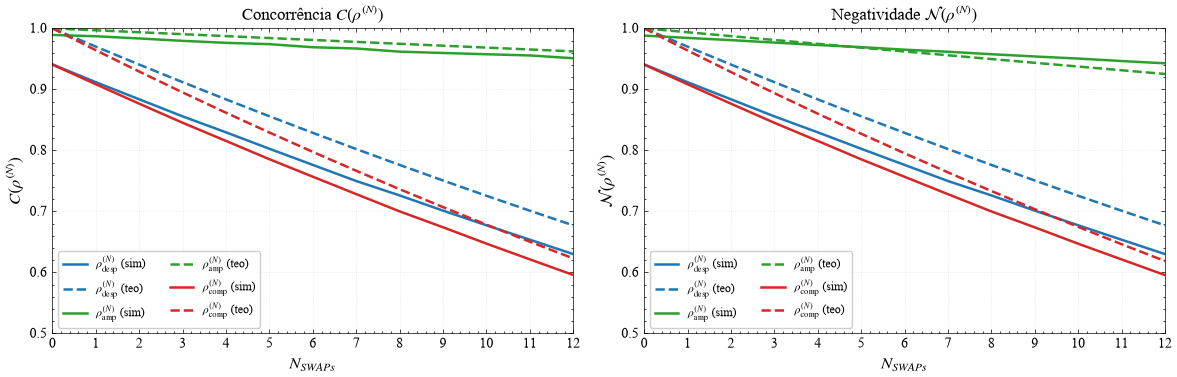

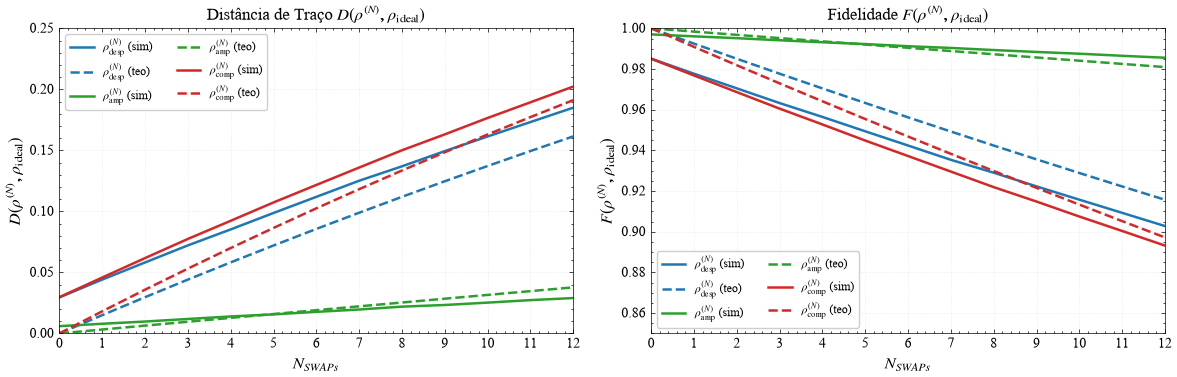

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# DADOS
# ============================================================

x = np.arange(0, 14)


# ============================================================
# CORES
# ============================================================

color_desp = "#1f77b4"
color_amp  = "#2ca02c"
color_comp = "#d62728"


# ============================================================
# FIGURA 1: CONCORRÊNCIA E NEGATIVIDADE
# ============================================================

with plt.style.context(["science", "no-latex"]):

    # --------------------------------------------------------
    # TIPOGRAFIA
    # --------------------------------------------------------

    plt.rcParams.update({
        "font.family": "Times New Roman",
        "mathtext.fontset": "stix",
        "font.size": 11,
        "axes.labelsize": 12,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 8.5,
    })


    fig, axs = plt.subplots(
        1, 2,
        figsize=(12, 4)
    )


    # ========================================================
    # CONCORRÊNCIA
    # ========================================================

    ax = axs[0]

    # --------------------------------------------------------
    # DEPOLARIZANTE
    # --------------------------------------------------------

    ax.plot(
        x,
        df_results_desp["Concurrence"],
        "-",
        color=color_desp,
        linewidth=1.8,
        label=r"$\rho^{(N)}_{\mathrm{desp}}$ (sim)"
    )

    ax.plot(
        x,
        df_desp["Concurrence"],
        "--",
        color=color_desp,
        linewidth=1.8,
        label=r"$\rho^{(N)}_{\mathrm{desp}}$ (teo)"
    )


    # --------------------------------------------------------
    # AMPLITUDE DAMPING
    # --------------------------------------------------------

    ax.plot(
        x,
        df_results_amp["Concurrence"],
        "-",
        color=color_amp,
        linewidth=1.8,
        label=r"$\rho^{(N)}_{\mathrm{amp}}$ (sim)"
    )

    ax.plot(
        x,
        df_amp["Concurrence"],
        "--",
        color=color_amp,
        linewidth=1.8,
        label=r"$\rho^{(N)}_{\mathrm{amp}}$ (teo)"
    )


    # --------------------------------------------------------
    # COMPOSTO
    # --------------------------------------------------------

    ax.plot(
        x,
        df_results_comp["Concurrence"],
        "-",
        color=color_comp,
        linewidth=1.8,
        label=r"$\rho^{(N)}_{\mathrm{comp}}$ (sim)"
    )

    ax.plot(
        x,
        df_comp["Concurrence"],
        "--",
        color=color_comp,
        linewidth=1.8,
        label=r"$\rho^{(N)}_{\mathrm{comp}}$ (teo)"
    )


    # --------------------------------------------------------
    # TÍTULO
    # --------------------------------------------------------

    ax.set_title(
        r"Concorrência $C(\rho^{(N)})$",
        fontsize=12
    )


    # --------------------------------------------------------
    # EIXOS
    # --------------------------------------------------------

    ax.set_xlabel(
        r"$N_{SWAPs}$"
    )

    ax.set_ylabel(
        r"$C(\rho^{(N)})$"
    )

    ax.set_xlim(0, 12)
    ax.set_xticks(x)

    ax.set_ylim(0.5, 1.0)


    # --------------------------------------------------------
    # GRID
    # --------------------------------------------------------

    ax.grid(
        True,
        which="major",
        linestyle=":",
        linewidth=0.5,
        alpha=0.35
    )


    # --------------------------------------------------------
    # LEGENDA
    # --------------------------------------------------------

    ax.legend(
        loc="lower left",
        ncol=2,
        frameon=True,
        framealpha=0.95,
        fontsize=8.5
    )


    # ========================================================
    # NEGATIVIDADE
    # ========================================================

    ax = axs[1]

    # --------------------------------------------------------
    # DEPOLARIZANTE
    # --------------------------------------------------------

    ax.plot(
        x,
        df_results_desp["Negativity"],
        "-",
        color=color_desp,
        linewidth=1.8,
        label=r"$\rho^{(N)}_{\mathrm{desp}}$ (sim)"
    )

    ax.plot(
        x,
        df_desp["Negativity"],
        "--",
        color=color_desp,
        linewidth=1.8,
        label=r"$\rho^{(N)}_{\mathrm{desp}}$ (teo)"
    )


    # --------------------------------------------------------
    # AMPLITUDE DAMPING
    # --------------------------------------------------------

    ax.plot(
        x,
        df_results_amp["Negativity"],
        "-",
        color=color_amp,
        linewidth=1.8,
        label=r"$\rho^{(N)}_{\mathrm{amp}}$ (sim)"
    )

    ax.plot(
        x,
        df_amp["Negativity"],
        "--",
        color=color_amp,
        linewidth=1.8,
        label=r"$\rho^{(N)}_{\mathrm{amp}}$ (teo)"
    )


    # --------------------------------------------------------
    # COMPOSTO
    # --------------------------------------------------------

    ax.plot(
        x,
        df_results_comp["Negativity"],
        "-",
        color=color_comp,
        linewidth=1.8,
        label=r"$\rho^{(N)}_{\mathrm{comp}}$ (sim)"
    )

    ax.plot(
        x,
        df_comp["Negativity"],
        "--",
        color=color_comp,
        linewidth=1.8,
        label=r"$\rho^{(N)}_{\mathrm{comp}}$ (teo)"
    )


    # --------------------------------------------------------
    # TÍTULO
    # --------------------------------------------------------

    ax.set_title(
        r"Negatividade $\mathcal{N}(\rho^{(N)})$",
        fontsize=12
    )


    # --------------------------------------------------------
    # EIXOS
    # --------------------------------------------------------

    ax.set_xlabel(
        r"$N_{SWAPs}$"
    )

    ax.set_ylabel(
        r"$\mathcal{N}(\rho^{(N)})$"
    )

    ax.set_xlim(0, 12)
    ax.set_xticks(x)

    ax.set_ylim(0.5, 1.0)


    # --------------------------------------------------------
    # GRID
    # --------------------------------------------------------

    ax.grid(
        True,
        which="major",
        linestyle=":",
        linewidth=0.5,
        alpha=0.35
    )


    # --------------------------------------------------------
    # LEGENDA
    # --------------------------------------------------------

    ax.legend(
        loc="lower left",
        ncol=2,
        frameon=True,
        framealpha=0.95,
        fontsize=8.5
    )


    # ========================================================
    # AJUSTE
    # ========================================================

    fig.tight_layout()


    fig.savefig(
        "concurrence_negativity.png",
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# FIGURA 2: DISTÂNCIA DE TRAÇO E FIDELIDADE
# ============================================================

with plt.style.context(["science", "no-latex"]):

    # --------------------------------------------------------
    # TIPOGRAFIA
    # --------------------------------------------------------

    plt.rcParams.update({
        "font.family": "Times New Roman",
        "mathtext.fontset": "stix",
        "font.size": 11,
        "axes.labelsize": 12,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 8.5,
    })


    fig, axs = plt.subplots(
        1, 2,
        figsize=(12, 4)
    )


    # ========================================================
    # DISTÂNCIA DE TRAÇO
    # ========================================================

    ax = axs[0]

    # --------------------------------------------------------
    # DEPOLARIZANTE
    # --------------------------------------------------------

    ax.plot(
        x,
        df_results_desp["Trace Distance"],
        "-",
        color=color_desp,
        linewidth=1.8,
        label=r"$\rho^{(N)}_{\mathrm{desp}}$ (sim)"
    )

    ax.plot(
        x,
        df_desp["Trace Distance"],
        "--",
        color=color_desp,
        linewidth=1.8,
        label=r"$\rho^{(N)}_{\mathrm{desp}}$ (teo)"
    )


    # --------------------------------------------------------
    # AMPLITUDE DAMPING
    # --------------------------------------------------------

    ax.plot(
        x,
        df_results_amp["Trace Distance"],
        "-",
        color=color_amp,
        linewidth=1.8,
        label=r"$\rho^{(N)}_{\mathrm{amp}}$ (sim)"
    )

    ax.plot(
        x,
        df_amp["Trace Distance"],
        "--",
        color=color_amp,
        linewidth=1.8,
        label=r"$\rho^{(N)}_{\mathrm{amp}}$ (teo)"
    )


    # --------------------------------------------------------
    # COMPOSTO
    # --------------------------------------------------------

    ax.plot(
        x,
        df_results_comp["Trace Distance"],
        "-",
        color=color_comp,
        linewidth=1.8,
        label=r"$\rho^{(N)}_{\mathrm{comp}}$ (sim)"
    )

    ax.plot(
        x,
        df_comp["Trace Distance"],
        "--",
        color=color_comp,
        linewidth=1.8,
        label=r"$\rho^{(N)}_{\mathrm{comp}}$ (teo)"
    )


    # --------------------------------------------------------
    # TÍTULO
    # --------------------------------------------------------

    ax.set_title(
        r"Distância de Traço $D(\rho^{(N)},\rho_{\mathrm{ideal}})$",
        fontsize=12
    )


    # --------------------------------------------------------
    # EIXOS
    # --------------------------------------------------------

    ax.set_xlabel(
        r"$N_{SWAPs}$"
    )

    ax.set_ylabel(
        r"$D(\rho^{(N)},\rho_{\mathrm{ideal}})$"
    )

    ax.set_xlim(0, 12)
    ax.set_xticks(x)

    ax.set_ylim(0, 0.25)


    # --------------------------------------------------------
    # GRID
    # --------------------------------------------------------

    ax.grid(
        True,
        which="major",
        linestyle=":",
        linewidth=0.5,
        alpha=0.35
    )


    # --------------------------------------------------------
    # LEGENDA
    # --------------------------------------------------------

    ax.legend(
        loc="upper left",
        ncol=2,
        frameon=True,
        framealpha=0.95,
        fontsize=8.5
    )


    # ========================================================
    # FIDELIDADE
    # ========================================================

    ax = axs[1]

    # --------------------------------------------------------
    # DEPOLARIZANTE
    # --------------------------------------------------------

    ax.plot(
        x,
        df_results_desp["Fidelity"],
        "-",
        color=color_desp,
        linewidth=1.8,
        label=r"$\rho^{(N)}_{\mathrm{desp}}$ (sim)"
    )

    ax.plot(
        x,
        df_desp["Fidelity"],
        "--",
        color=color_desp,
        linewidth=1.8,
        label=r"$\rho^{(N)}_{\mathrm{desp}}$ (teo)"
    )


    # --------------------------------------------------------
    # AMPLITUDE DAMPING
    # --------------------------------------------------------

    ax.plot(
        x,
        df_results_amp["Fidelity"],
        "-",
        color=color_amp,
        linewidth=1.8,
        label=r"$\rho^{(N)}_{\mathrm{amp}}$ (sim)"
    )

    ax.plot(
        x,
        df_amp["Fidelity"],
        "--",
        color=color_amp,
        linewidth=1.8,
        label=r"$\rho^{(N)}_{\mathrm{amp}}$ (teo)"
    )


    # --------------------------------------------------------
    # COMPOSTO
    # --------------------------------------------------------

    ax.plot(
        x,
        df_results_comp["Fidelity"],
        "-",
        color=color_comp,
        linewidth=1.8,
        label=r"$\rho^{(N)}_{\mathrm{comp}}$ (sim)"
    )

    ax.plot(
        x,
        df_comp["Fidelity"],
        "--",
        color=color_comp,
        linewidth=1.8,
        label=r"$\rho^{(N)}_{\mathrm{comp}}$ (teo)"
    )


    # --------------------------------------------------------
    # TÍTULO
    # --------------------------------------------------------

    ax.set_title(
        r"Fidelidade $F(\rho^{(N)},\rho_{\mathrm{ideal}})$",
        fontsize=12
    )


    # --------------------------------------------------------
    # EIXOS
    # --------------------------------------------------------

    ax.set_xlabel(
        r"$N_{SWAPs}$"
    )

    ax.set_ylabel(
        r"$F(\rho^{(N)},\rho_{\mathrm{ideal}})$"
    )

    ax.set_xlim(0, 12)
    ax.set_xticks(x)

    ax.set_ylim(0.85, 1.0)


    # --------------------------------------------------------
    # GRID
    # --------------------------------------------------------

    ax.grid(
        True,
        which="major",
        linestyle=":",
        linewidth=0.5,
        alpha=0.35
    )


    # --------------------------------------------------------
    # LEGENDA
    # --------------------------------------------------------

    ax.legend(
        loc="lower left",
        ncol=2,
        frameon=True,
        framealpha=0.95,
        fontsize=8.5
    )


    # ========================================================
    # AJUSTE
    # ========================================================

    fig.tight_layout()


    fig.savefig(
        "trace_distance_fidelity.png",
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()